# HASTS206 Applied Demographic Analysis: Assignment 2
**University of Zimbabwe, Department of Mathematics and Computational Sciences**

> **All figures in this notebook are HYPOTHETICAL.** The data are synthetic and the district labels are illustrative.

**How to run:** place the original CSVs in `data/`, then run all cells from the repository root (`Kernel > Restart & Run All`). All paths are relative. Outputs consumed by Power BI are written to `outputs/`.

| Section | Content |
|---|---|
| 0 | Setup and data-quality log |
| 1 | Population structure and mortality (pyramids, ratios, balance, rates, abridged life table) |
| 2 | Population projections (arithmetic, geometric, cohort-component, sensitivity) |
| 3 | Three-state continuous-time Markov model (H, I, D) |
| 4 | District clustering (k-means) |
| 5 | Exports for Power BI, reconciliation figures |
| 6 | What-if cell for the recorded presentation |

Each block of code is followed by a **Notes** cell that interprets what was just executed.

In [2]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch
from scipy.linalg import expm
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
pd.options.display.float_format = lambda v: f'{v:,.0f}' if float(v).is_integer() else f'{v:,.4f}'
pd.options.display.width = 200
pd.options.display.max_columns = 40
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})

DATA, OUT = Path('data'), Path('outputs')
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
HYP = '(hypothetical data)'
f0 = lambda x: f'{x:,.0f}'; f1 = lambda x: f'{x:,.1f}'; f2 = lambda x: f'{x:,.2f}'; f3 = lambda x: f'{x:,.3f}'; f4 = lambda x: f'{x:,.4f}'; pc = lambda x: f'{100*x:.1f}%'   # formatting helpers used in the Notes cells
KEY = {}          # key results saved to outputs/key_results.json for the PDF report

districts = pd.read_csv(DATA / 'districts.csv')
age_sex   = pd.read_csv(DATA / 'age_sex.csv')
life_in   = pd.read_csv(DATA / 'life_table_inputs.csv')
scen      = pd.read_csv(DATA / 'projection_scenarios.csv')
ins       = pd.read_csv(DATA / 'insured_transitions.csv')

AGES = sorted(age_sex.age_start.unique())
AGE_LAB = {a: (f'{a}-{a+4}' if a < 85 else '85+') for a in AGES}
for n, d in [('districts', districts), ('age_sex', age_sex), ('life_table_inputs', life_in), ('projection_scenarios', scen), ('insured_transitions', ins)]:
    print(f'{n:22s} rows={len(d):4d} cols={d.shape[1]}')

districts              rows=  24 cols=10
age_sex                rows= 864 cols=9
life_table_inputs      rows=  18 cols=5
projection_scenarios   rows=   3 cols=6
insured_transitions    rows=  96 cols=6


## 0. Data-quality log
The original CSVs are never overwritten. Every check below is recorded in a log (saved to `outputs/data_quality_log.csv`) together with the cleaning decision taken in code.

In [4]:
log = []
def check(area, test, result, status, action=''):
    log.append(dict(area=area, test=test, result=str(result), status=status, action=action))
ok = lambda b: 'PASS' if b else 'FAIL'

# --- row counts and keys
exp = {'districts': 24, 'age_sex': 24 * 18 * 2, 'life_table_inputs': 18, 'projection_scenarios': 3, 'insured_transitions': 24 * 2 * 2}
for n, d in [('districts', districts), ('age_sex', age_sex), ('life_table_inputs', life_in), ('projection_scenarios', scen), ('insured_transitions', ins)]:
    check('Row count', n, f'{len(d)} (expected {exp[n]})', ok(len(d) == exp[n]))
check('Key', 'districts.district_id unique', districts.district_id.is_unique, ok(districts.district_id.is_unique))
check('Key', 'age_sex (district_id, age_start, sex) unique', not age_sex.duplicated(['district_id', 'age_start', 'sex']).any(), ok(not age_sex.duplicated(['district_id', 'age_start', 'sex']).any()))
check('Key', 'life_table age_start unique', life_in.age_start.is_unique, ok(life_in.age_start.is_unique))
check('Key', 'projection_scenarios scenario unique', scen.scenario.is_unique, ok(scen.scenario.is_unique))
check('Key', 'insured (district_id, origin, destination) unique', not ins.duplicated(['district_id', 'origin', 'destination']).any(), ok(not ins.duplicated(['district_id', 'origin', 'destination']).any()))

# --- join cardinality: age_sex (many) -> districts (one)
j = age_sex.merge(districts[['district_id']], on='district_id', how='left', validate='many_to_one', indicator=True)
check('Join', 'age_sex -> districts is many-to-one, no orphans, no row inflation', f'{len(j)} rows after join, orphans={(j._merge != "both").sum()}', ok(len(j) == len(age_sex) and (j._merge == 'both').all()))
per_d = age_sex.groupby('district_id').size()
check('Join', 'rows per district in age_sex', f'min={per_d.min()}, max={per_d.max()}', ok((per_d == 36).all()))
ji = ins.merge(districts[['district_id']], on='district_id', how='left', validate='many_to_one')
check('Join', 'insured_transitions -> districts many-to-one (4 rows per district)', f'{len(ji)} rows; rows per district = {ins.groupby("district_id").size().unique().tolist()}', ok(len(ji) == len(ins)))

# --- coverage
cov = age_sex.groupby('district_id').agg(bands=('age_start', 'nunique'), sexes=('sex', 'nunique'))
check('Coverage', 'age bands 0..85 (18) and sexes F,M in every district', f'bands={cov.bands.unique().tolist()}, sexes={cov.sexes.unique().tolist()}', ok((cov.bands == 18).all() and (cov.sexes == 2).all()))
check('Coverage', 'age_start values', AGES, ok(AGES == list(range(0, 90, 5))))
check('Coverage', 'life-table bands match age_sex bands', life_in.age_start.tolist() == AGES, ok(life_in.age_start.tolist() == AGES))

# --- missing indicators
miss = pd.concat([d.isna().sum().rename(n) for n, d in [('districts', districts), ('age_sex', age_sex), ('life', life_in), ('scen', scen), ('ins', ins)]], axis=1)
miss_list = {c: districts.loc[districts[c].isna(), 'district_id'].tolist() for c in districts.columns if districts[c].isna().any()}
check('Missing', 'districts.piped_water_pct missing', miss_list, 'FLAG', 'Left blank in raw data. Imputed ONLY in the clustering step (Section 4) with an explicit flag column; sensitivity checked.')
check('Missing', 'age_sex, scenarios, insured: any blanks', int(age_sex.isna().sum().sum() + scen.isna().sum().sum() + ins.isna().sum().sum()), ok(age_sex.isna().sum().sum() + scen.isna().sum().sum() + ins.isna().sum().sum() == 0))
lt_blank = life_in[life_in.interval_years.isna() | life_in.ax.isna()].age_start.tolist()
check('Missing', 'life table blanks (interval_years, ax)', f'only at age_start={lt_blank}', ok(lt_blank == [85]), 'Structural (open interval). Handled via L85+ = l85/m85+.')

# --- valid ranges
num_cols = ['population_2025', 'baseline_deaths_2025', 'arrivals_2025', 'departures_2025', 'births_to_women_2025']
check('Range', 'age_sex counts non-negative integers', bool((age_sex[num_cols] >= 0).all().all()), ok((age_sex[num_cols] >= 0).all().all()))
check('Range', 'survival_5yr in (0,1]', f'{age_sex.survival_5yr.min():.4f} to {age_sex.survival_5yr.max():.4f}', ok(age_sex.survival_5yr.between(0, 1).all()))
check('Range', 'baseline deaths <= population', bool((age_sex.baseline_deaths_2025 <= age_sex.population_2025).all()), ok((age_sex.baseline_deaths_2025 <= age_sex.population_2025).all()))
fb = age_sex[age_sex.births_to_women_2025 > 0]
check('Range', 'births only in female rows, ages 15-49', f'male rows with births={(age_sex[(age_sex.sex=="M")].births_to_women_2025>0).sum()}; ages with births={sorted(fb.age_start.unique())}', ok((fb.sex == 'F').all() and fb.age_start.between(15, 45).all()))
check('Range', 'piped_water_pct within 0-100', f'{districts.piped_water_pct.min()} to {districts.piped_water_pct.max()}', ok(districts.piped_water_pct.dropna().between(0, 100).all()))
check('Range', 'life table ax within (0, interval)', 'all 5-year bands', ok(((life_in.ax > 0) & (life_in.ax < life_in.interval_years)).iloc[:-1].all()))
check('Range', 'scenario multipliers positive, newborn survival in (0,1)', 'Low<Base<High ordering holds for fertility, arrivals, newborn survival', ok(scen.fertility_multiplier.is_monotonic_increasing and scen.arrivals_multiplier.is_monotonic_increasing and scen.departures_multiplier.is_monotonic_decreasing))

# --- reconciliation of totals and events
agg = age_sex.groupby('district_id').agg(pop2025=('population_2025', 'sum'), base_deaths=('baseline_deaths_2025', 'sum'),
        arr=('arrivals_2025', 'sum'), dep=('departures_2025', 'sum'), births_f=('births_to_women_2025', 'sum'))
rec = districts.merge(agg, left_on='district_id', right_index=True, validate='one_to_one')
rec['recon_2026'] = rec.pop2025 + rec.births_2025 - rec.deaths_2025 + rec.arrivals_2025 - rec.departures_2025
rec['balance_gap'] = rec.population_2026 - rec.recon_2026
rec['newborn_deaths_implied'] = rec.deaths_2025 - rec.base_deaths
check('Reconcile', 'births: districts vs sum of age_sex female rows', f'max abs diff = {(rec.births_2025 - rec.births_f).abs().max()}', ok((rec.births_2025 == rec.births_f).all()))
check('Reconcile', 'arrivals: districts vs age_sex', f'max abs diff = {(rec.arrivals_2025 - rec.arr).abs().max()}', ok((rec.arrivals_2025 == rec.arr).all()))
check('Reconcile', 'departures: districts vs age_sex', f'max abs diff = {(rec.departures_2025 - rec.dep).abs().max()}', ok((rec.departures_2025 == rec.dep).all()))
check('Reconcile', 'balancing equation: P2025 + B - D + I - E = reported P2026', f'max abs gap = {rec.balance_gap.abs().max()} persons', ok((rec.balance_gap == 0).all()))
check('Reconcile', 'district deaths vs baseline deaths (scope difference)', f'district deaths exceed baseline deaths in {(rec.newborn_deaths_implied>0).sum()}/24 districts; total gap = {rec.newborn_deaths_implied.sum():,}', 'EXPLAINED',
      'Baseline deaths cover only residents present on 1 Jan 2025 (classified by baseline age). District deaths also include deaths among 2025 births. The gap is therefore the implied deaths of 2025 births and must NOT be treated as an error.')

# --- Markov file repeated-field conventions
rep = ins.groupby(['district_id', 'origin']).agg(n_exp=('exposure_py', 'nunique'), n_init=('initial_lives', 'nunique'), rows=('destination', 'size'))
check('Markov file', 'exposure_py and initial_lives repeated identically across the 2 destinations', f'unique values per district-origin: exposure={rep.n_exp.unique().tolist()}, initial={rep.n_init.unique().tolist()}, rows={rep.rows.unique().tolist()}', ok((rep.n_exp == 1).all() and (rep.n_init == 1).all()),
      'Count exposure and initial_lives ONCE per district-origin (drop_duplicates) to avoid double counting.')
check('Markov file', 'origins/destinations valid (H->I,D ; I->H,D)', sorted(set(zip(ins.origin, ins.destination))), ok(set(zip(ins.origin, ins.destination)) == {('H', 'I'), ('H', 'D'), ('I', 'H'), ('I', 'D')}))
check('Markov file', 'counts non-negative; exposure positive', f'min exposure={ins.exposure_py.min()}', ok((ins.transition_count >= 0).all() and (ins.exposure_py > 0).all()))
check('Cleaning', 'Original CSVs unchanged; no rows dropped', 'All derived tables are built in memory and exported separately to outputs/', 'DONE')

dq = pd.DataFrame(log)
dq.to_csv(OUT / 'data_quality_log.csv', index=False)
KEY['dq_pass'] = int((dq.status == 'PASS').sum()); KEY['dq_total'] = len(dq); KEY['dq_fail'] = int((dq.status == 'FAIL').sum())
dq

,area,test,result,status,action
0,Row count,districts,24 (expected 24),PASS,
1,Row count,age_sex,864 (expected 864),PASS,
2,Row count,life_table_inputs,18 (expected 18),PASS,
3,Row count,projection_scenarios,3 (expected 3),PASS,
4,Row count,insured_transitions,96 (expected 96),PASS,
5,Key,districts.district_id unique,True,PASS,
6,Key,"age_sex (district_id, age_start, sex) unique",True,PASS,
7,Key,life_table age_start unique,True,PASS,
8,Key,projection_scenarios scenario unique,True,PASS,
9,Key,"insured (district_id, origin, destination) unique",True,PASS,


**Notes: data-quality log.**
- 32 of 35 checks pass outright and 0 fail. The remaining entries are *flags* that were handled by an explicit decision: two blank `piped_water_pct` values (D04, D17), structural blanks at the open 85+ interval, and the deaths scope difference.
- Keys are unique, `age_sex` joins to `districts` many-to-one with no orphans and no row inflation (864 rows before and after), and every district has all 18 age bands for both sexes.
- The Markov file repeats `exposure_py` and `initial_lives` on both destination rows of each district-origin. This is confirmed (one unique value per district-origin) and is handled by `drop_duplicates` in Section 3.
- **Decision:** nothing is deleted or edited in the raw CSVs. Missing water values stay missing here and are imputed only in the clustering step, flagged by `water_imputed`.

In [5]:
# Population-balance reconciliation for all 24 districts, plus the deaths scope difference
rec[['district_id', 'pop2025', 'births_2025', 'deaths_2025', 'arrivals_2025', 'departures_2025', 'recon_2026', 'population_2026', 'balance_gap', 'base_deaths', 'newborn_deaths_implied']].assign(
    newborn_deaths_per_100_births=lambda x: 100 * x.newborn_deaths_implied / x.births_2025).round(2)

,district_id,pop2025,births_2025,deaths_2025,arrivals_2025,departures_2025,recon_2026,population_2026,balance_gap,base_deaths,newborn_deaths_implied,newborn_deaths_per_100_births
0,D01,172445,3939,2166,2460,2926,173752,173752,0,2119,47,1.1900
1,D02,112211,2480,1173,2705,1618,114605,114605,0,1143,30,1.2100
2,D03,77907,1008,1639,1278,1458,77096,77096,0,1627,12,1.1900
3,D04,95654,2268,1239,1303,1655,96331,96331,0,1212,27,1.1900
4,D05,152444,3469,1597,3910,1749,156477,156477,0,1555,42,1.2100
5,D06,59525,774,1217,988,1063,59007,59007,0,1208,9,1.1600
6,D07,44047,935,552,581,682,44329,44329,0,541,11,1.1800
7,D08,55286,1264,580,1416,712,56674,56674,0,565,15,1.1900
8,D09,107511,1277,2178,1850,2002,106458,106458,0,2163,15,1.1700
9,D10,111451,2405,1372,1559,1664,112379,112379,0,1343,29,1.2100


Done by MAKUYA Panashe KC

**Notes: reconciliation and the deaths scope difference.**
- For all 24 districts, P(2025) + births - deaths + arrivals - departures equals the reported 1 January 2026 population exactly (gap = 0 persons), and births, arrivals and departures in `districts.csv` equal the sums over `age_sex.csv`.
- **Deaths do not reconcile, by design.** `baseline_deaths_2025` covers only residents present on 1 January 2025, classified by age at baseline. District deaths add the deaths among babies born during 2025, who are not in the baseline population. The gap is therefore the implied number of deaths among 2025 births (621 in total, about 1.20 per 100 births). Using baseline deaths in a balancing equation would leave the 2026 reconstruction short by exactly that amount.

## 1. Population structure and mortality
### 1(a) Selecting two contrasting districts, pyramids and dependency ratios
**Selection rule (explicit and reproducible).** I compute the age structure for all 24 districts, restrict to pairs of districts whose 1 January 2025 populations differ by less than 2%, and pick the pair with the largest gap in the ageing index (65+ per 100 under-15s). Matching on size means differences in the pyramids reflect age structure and not scale.

In [6]:
def structure(df):
    """Age-structure indicators for one district's age_sex rows (1 Jan 2025)."""
    p = df.groupby('age_start').population_2025.sum()
    sx = df.groupby('sex').population_2025.sum()
    tot = p.sum(); kids = p[p.index < 15].sum(); work = p[(p.index >= 15) & (p.index < 65)].sum(); old = p[p.index >= 65].sum()
    return dict(pop2025=tot, females=sx['F'], males=sx['M'], sex_ratio=100 * sx['M'] / sx['F'], share_u15=kids / tot, share_65p=old / tot,
                ydr=100 * kids / work, odr=100 * old / work, ageing_index=100 * old / kids)

struct = pd.DataFrame({d: structure(g) for d, g in age_sex.groupby('district_id')}).T
struct.index.name = 'district_id'

cands = []
ids = struct.index.tolist()
for i in range(len(ids)):
    for k in range(i + 1, len(ids)):
        a, b = ids[i], ids[k]
        if abs(struct.pop2025[a] - struct.pop2025[b]) / max(struct.pop2025[a], struct.pop2025[b]) < 0.02:
            cands.append((a, b, abs(struct.ageing_index[a] - struct.ageing_index[b])))
cands = pd.DataFrame(cands, columns=['district_a', 'district_b', 'ageing_index_gap']).sort_values('ageing_index_gap', ascending=False)
print(cands.head(5).to_string(index=False))
SEL_A, SEL_B = cands.iloc[0].district_a, cands.iloc[0].district_b
# order so that SEL_Y is the young district and SEL_O the ageing one
SEL_Y, SEL_O = sorted([SEL_A, SEL_B], key=lambda d: -struct.share_u15[d])
print(f'\nSelected: young district = {SEL_Y}, ageing district = {SEL_O}')
struct.loc[[SEL_Y, SEL_O]].T

district_a district_b  ageing_index_gap
       D01        D24          236.0989
       D13        D24          235.5462
       D11        D21          194.8635
       D20        D22           46.5971
       D19        D23           45.2119

Selected: young district = D01, ageing district = D24


district_id,D01,D24
pop2025,"172,445","172,718"
females,"91,570","88,728"
males,"80,875","83,990"
sex_ratio,88.3204,94.6601
share_u15,0.2927,0.0968
share_65p,0.1463,0.2769
ydr,52.1912,15.4535
odr,26.0889,44.2104
ageing_index,49.9871,286.0860


**Notes: choice of districts.**
- D01 and D24 have almost identical populations (172,445 and 172,718) but opposite age structures: under-15 share 29.3% vs 9.7%, and 65+ share 14.6% vs 27.7%. The ageing index (65+ per 100 under-15s) is 50 vs 286.
- Because size is matched, any difference in rates and ratios is due to structure and behaviour and not scale. D24 is used for the age-sex projection (reason given at the start of Section 2).

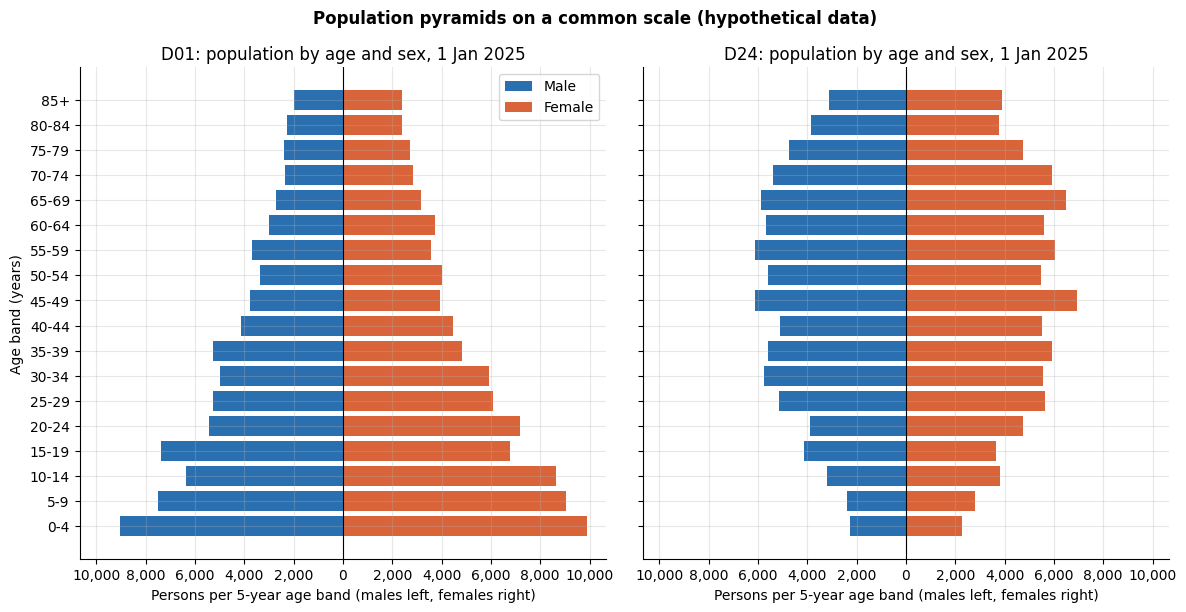

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6.2), sharex=True, sharey=True)
xmax = age_sex[age_sex.district_id.isin([SEL_Y, SEL_O])].population_2025.max() * 1.08
for ax, d in zip(axes, [SEL_Y, SEL_O]):
    g = age_sex[age_sex.district_id == d]
    f = g[g.sex == 'F'].set_index('age_start').population_2025.reindex(AGES)
    m = g[g.sex == 'M'].set_index('age_start').population_2025.reindex(AGES)
    y = np.arange(len(AGES))
    ax.barh(y, -m.values, color='#2a6fb0', label='Male'); ax.barh(y, f.values, color='#d9643a', label='Female')
    ax.set_yticks(y); ax.set_yticklabels([AGE_LAB[a] for a in AGES]); ax.set_xlim(-xmax, xmax)
    ticks = np.arange(-10000, 10001, 2000); ax.set_xticks(ticks); ax.set_xticklabels([f'{abs(t):,}' for t in ticks])
    ax.set_title(f'{d}: population by age and sex, 1 Jan 2025'); ax.set_xlabel('Persons per 5-year age band (males left, females right)')
    ax.axvline(0, color='k', lw=.8)
axes[0].set_ylabel('Age band (years)'); axes[0].legend(loc='upper right')
fig.suptitle(f'Population pyramids on a common scale {HYP}', fontweight='bold')
fig.tight_layout(); fig.savefig(FIG / 'pyramids.png', dpi=150, bbox_inches='tight')

**Notes: pyramids.** Units are **persons per 5-year age band**, and both panels share the same horizontal axis (up to 10,000) so bar lengths are directly comparable. D01 has an expansive, wide-based pyramid, with about 18,922 children aged 0-4. D24 is constrictive: it has only 4,535 children aged 0-4, a bulge at ages 25-69 and a heavy female top (85+). All data are hypothetical.

In [8]:
ratio_tbl = struct.loc[[SEL_Y, SEL_O], ['pop2025', 'females', 'males', 'sex_ratio', 'ydr', 'odr', 'share_u15', 'share_65p']].T
ratio_tbl.index = ['Total population 1 Jan 2025', 'Females', 'Males', 'Sex ratio (males per 100 females)', 'Youth dependency ratio (0-14 per 100 aged 15-64)',
                   'Old-age dependency ratio (65+ per 100 aged 15-64)', 'Share under 15', 'Share aged 65+']
KEY['select'] = dict(young=SEL_Y, old=SEL_O, struct=struct.loc[[SEL_Y, SEL_O]].round(4).to_dict('index'))
ratio_tbl

district_id,D01,D24
Total population 1 Jan 2025,"172,445","172,718"
Females,"91,570","88,728"
Males,"80,875","83,990"
Sex ratio (males per 100 females),88.3204,94.6601
Youth dependency ratio (0-14 per 100 aged 15-64),52.1912,15.4535
Old-age dependency ratio (65+ per 100 aged 15-64),26.0889,44.2104
Share under 15,0.2927,0.0968
Share aged 65+,0.1463,0.2769


**Notes: ratios at 1 January 2025.**
- **Sex ratio** (males per 100 females): D01 88.3, D24 94.7. Both districts have a female surplus (fewer than 100 males per 100 females), and the surplus is much larger in D01.
- **Youth dependency ratio** (0-14 per 100 aged 15-64): 52.2 vs 15.5. **Old-age dependency ratio** (65+ per 100 aged 15-64): 26.1 vs 44.2.
- **One contrast interpreted:** in D01, the dependency burden is overwhelmingly *young* (youth ratio about 2.0 times the old-age ratio), implying pressure on schools, child health and maternity services. In D24 the burden is reversed (old-age ratio about 2.9 times the youth ratio), implying pressure on elderly care, chronic-disease services and pensions. The *total* dependency ratios are 78.3 vs 59.7, but the bigger difference is composition (young vs old dependants), which calls for very different services.

### 1(b) Population balance and demographic rates (calendar 2025)
Balancing equation: **P(2026) = P(2025) + B - D + I - E**, where P(2025) is the sum of the age-sex file. Rates are per 1,000 using the **mean of the opening 2025 and 2026 stocks** as approximate mid-year exposure.

In [9]:
sel = rec.set_index('district_id').loc[[SEL_Y, SEL_O]].copy()
sel['exposure'] = (sel.pop2025 + sel.population_2026) / 2
sel['CBR'] = 1000 * sel.births_2025 / sel.exposure
sel['CDR'] = 1000 * sel.deaths_2025 / sel.exposure
sel['NMR'] = 1000 * (sel.arrivals_2025 - sel.departures_2025) / sel.exposure
sel['NIR'] = sel.CBR - sel.CDR
sel['growth_per_1000'] = sel.NIR + sel.NMR
sel['growth_pct'] = sel.growth_per_1000 / 10
sel['check_growth_pct'] = 100 * (sel.population_2026 / sel.pop2025 - 1)
cols = ['pop2025', 'births_2025', 'deaths_2025', 'arrivals_2025', 'departures_2025', 'recon_2026', 'population_2026', 'balance_gap', 'exposure']
print('Balancing equation (persons):'); print(sel[cols].T.to_string())
print('\nRates per 1,000 mean-stock residents:'); print(sel[['CBR', 'CDR', 'NIR', 'NMR', 'growth_per_1000']].round(2).T.to_string())
print('\nSimple growth rate (%): rates-based vs stocks-based (they differ because rates use the mean-stock denominator):')
print(sel[['growth_pct', 'check_growth_pct']].round(3).T.to_string())
print('\nTotal baseline population, all 24 districts:', f'{age_sex.population_2025.sum():,}')
KEY['balance'] = sel[cols + ['CBR', 'CDR', 'NIR', 'NMR', 'growth_pct']].round(3).to_dict('index')

Balancing equation (persons):
district_id              D01          D24
pop2025              172,445      172,718
births_2025            3,939        2,197
deaths_2025            2,166        3,618
arrivals_2025          2,460        2,841
departures_2025        2,926        3,089
recon_2026           173,752      171,049
population_2026      173,752      171,049
balance_gap                0            0
exposure        173,098.5000 171,883.5000

Rates per 1,000 mean-stock residents:
district_id         D01     D24
CBR             22.7600 12.7800
CDR             12.5100 21.0500
NIR             10.2400 -8.2700
NMR             -2.6900 -1.4400
growth_per_1000  7.5500 -9.7100

Simple growth rate (%): rates-based vs stocks-based (they differ because rates use the mean-stock denominator):
district_id         D01     D24
growth_pct       0.7550 -0.9710
check_growth_pct 0.7580 -0.9660

Total baseline population, all 24 districts: 2,636,363
